In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model = "gemini-2.5-flash")

In [4]:
class BlogState(TypedDict):
    title: str
    outline : str
    content : str

In [5]:
def create_outline(state: BlogState) -> BlogState:
    title = state['title']

    prompt = f"Generate a detailed outline for a blog on the topic - {title}"
    outline = model.invoke(prompt).content

    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f"Generate a detailed blog on the title - {title} using the following outline \n {outline}"
    blog = model.invoke(prompt).content

    state['content'] = blog

    return state

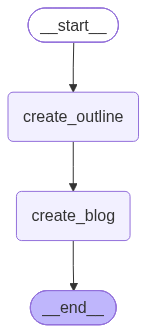

In [7]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()
workflow

In [8]:
initial_state = {'title' : "AI"}
final_state = workflow.invoke(initial_state)

final_state

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'title': 'AI',
 'outline': 'Here\'s a detailed outline for a blog post on the topic of Artificial Intelligence, designed to be comprehensive yet accessible for a general audience.\n\n---\n\n**Blog Title Ideas:**\n*   Decoding AI: Your Essential Guide to Artificial Intelligence\n*   AI Explained: Understanding the Revolution Shaping Our World\n*   Beyond the Hype: A Deep Dive into Artificial Intelligence\n*   The Future is Now: Everything You Need to Know About AI\n\n---\n\n**Detailed Blog Post Outline: Decoding AI: Your Essential Guide to Artificial Intelligence**\n\n**I. Introduction: The AI Awakening**\n    *   **A. Hook:** Start with a relatable example of AI in everyday life (e.g., Netflix recommendations, ChatGPT, self-driving car news, Alexa/Siri).\n    *   **B. What is AI (Briefly):** A simple, non-technical definition – machines performing tasks that typically require human intelligence.\n    *   **C. Why This Blog Post Matters:**\n        *   Demystify AI beyond the sci-fi na

In [9]:
print(final_state['content'])

## Decoding AI: Your Essential Guide to Artificial Intelligence

From the personalized recommendations that greet you on Netflix to the voice assistant that sets your morning alarm, Artificial Intelligence (AI) isn't just a futuristic concept – it's woven into the fabric of our daily lives. You've likely encountered its capabilities through the latest buzz about ChatGPT, or perhaps seen news about self-driving cars promising to revolutionize transportation. AI is no longer confined to the pages of science fiction; it's here, it's evolving rapidly, and it's reshaping our world in profound ways.

But what exactly *is* AI beyond the headlines and sci-fi narratives? This blog post aims to demystify Artificial Intelligence, moving beyond the hype to provide a clear, foundational understanding for everyone. We'll explore what AI truly means, its various forms, how it works, and its far-reaching impact. Artificial Intelligence is not just a technological marvel but a transformative force resh